In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import wfdb


from pathlib import Path
from torch.utils.data import Dataset, DataLoader

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [4]:
PROJECT_ROOT = Path("..")

PTBXL_DIR = PROJECT_ROOT / "data" / "raw" / "ptb-xl"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR = PROJECT_ROOT / "reports"

INTERPRETATION_DIR = REPORTS_DIR / "interpretation"

INTERPRETATION_DIR.mkdir(parents=True, exist_ok=True)

print("PTB-XL:", PTBXL_DIR)
print("Processed:", PROCESSED_DIR)
print("Model:", MODELS_DIR)
print("Interpretation:", INTERPRETATION_DIR)

PTB-XL: ../data/raw/ptb-xl
Processed: ../data/processed
Model: ../models
Interpretation: ../reports/interpretation


In [5]:
test_df = pd.read_csv(PROCESSED_DIR / "ptbxl_test.csv")

print("Test shape:", test_df.shape)

test_df.head()

Test shape: (2158, 36)


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,filename_lr,filename_hr,scp_codes_dict,diagnostic_classes,label_NORM,label_MI,label_STTC,label_CD,label_HYP,num_labels
0,9,18792.0,55.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-12-08 09:44:43,...,records100/00000/00009_lr,records500/00000/00009_hr,"{'NORM': 100.0, 'SR': 0.0}",['NORM'],1,0,0,0,0,1
1,38,17076.0,40.0,0,NaN,72.0,2.0,0.0,CS-12 E,1985-02-15 11:48:22,...,records100/00000/00038_lr,records500/00000/00038_hr,"{'NORM': 100.0, 'SR': 0.0}",['NORM'],1,0,0,0,0,1
2,40,19501.0,60.0,0,NaN,85.0,2.0,0.0,CS-12 E,1985-02-20 11:43:45,...,records100/00000/00040_lr,records500/00000/00040_hr,"{'NORM': 80.0, 'SR': 0.0}",['NORM'],1,0,0,0,0,1
3,57,16063.0,26.0,0,NaN,93.0,2.0,0.0,CS-12 E,1985-06-06 11:32:43,...,records100/00000/00057_lr,records500/00000/00057_hr,"{'NORM': 100.0, 'SR': 0.0}",['NORM'],1,0,0,0,0,1
4,59,19475.0,54.0,0,NaN,67.0,2.0,0.0,CS-12 E,1985-06-12 06:36:01,...,records100/00000/00059_lr,records500/00000/00059_hr,"{'NORM': 100.0, 'SR': 0.0}",['NORM'],1,0,0,0,0,1


In [6]:
TARGET_CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

label_columns = [f"label_{cls}" for cls in TARGET_CLASSES]

print(TARGET_CLASSES)

['NORM', 'MI', 'STTC', 'CD', 'HYP']


In [7]:
def normalize_ecg(signal):
    """
    Normalize each ECG lead independently.
    """

    mean = signal.mean(axis=0, keepdims=True)

    std = signal.std(axis=0, keepdims=True)

    std = np.where(std < 1e-8, 1.0, std)

    return (signal - mean) / std

In [8]:
class PTBXLSignalDataset(Dataset):

    def __init__(self, dataframe, base_dir, label_columns):
        self.dataframe = dataframe.reset_index(drop=True)

        self.base_dir = Path(base_dir)

        self.label_columns = label_columns

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        record_path = self.base_dir / row["filename_lr"]

        record = wfdb.rdrecord(str(record_path))

        signal = record.p_signal.astype(np.float32)

        signal = normalize_ecg(signal)

        # samples × leads
        # ->
        # leads × samples
        signal = signal.T

        labels = row[label_columns].to_numpy(dtype=np.float32)

        return (
            torch.tensor(signal, dtype=torch.float32),
            torch.tensor(labels, dtype=torch.float32),
        )

In [9]:
test_dataset = PTBXLSignalDataset(test_df, PTBXL_DIR, label_columns)

print("Test samples:", len(test_dataset))

Test samples: 2158


In [10]:
class ECGCNN(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [11]:
model = ECGCNN(num_classes=len(TARGET_CLASSES))

model = model.to(device)

model_path = MODELS_DIR / "ptbxl_cnn_baseline.pt"

model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))

model.eval()

print("Loaded:", model_path)

Loaded: ../models/ptbxl_cnn_baseline.pt


In [12]:
sample_index = 0

X, y = test_dataset[sample_index]

print("Input shape:", X.shape)

print("True labels:", y.numpy())

Input shape: torch.Size([12, 1000])
True labels: [1. 0. 0. 0. 0.]


In [13]:
true_classes = [TARGET_CLASSES[i] for i, value in enumerate(y.numpy()) if value == 1]

print("True classes:", true_classes)

True classes: ['NORM']


In [14]:
X_model = X.unsqueeze(0).to(device)

with torch.no_grad():

    logits = model(X_model)

    probabilities = torch.sigmoid(logits)

probabilities = probabilities.cpu().numpy()[0]

prediction_df = pd.DataFrame({"class": TARGET_CLASSES, "probability": probabilities})

prediction_df

,class,probability
0,NORM,0.950158
1,MI,0.004647
2,STTC,0.010766
3,CD,0.036971
4,HYP,0.009720


In [15]:
thresholds = {"NORM": 0.47, "MI": 0.21, "STTC": 0.42, "CD": 0.45, "HYP": 0.23}

predicted_classes = [
    class_name
    for class_name, probability in zip(TARGET_CLASSES, probabilities)
    if probability >= thresholds[class_name]
]

print("Predicted classes:", predicted_classes)

Predicted classes: ['NORM']


In [16]:
predicted_class_index = int(np.argmax(probabilities))

selected_class = TARGET_CLASSES[predicted_class_index]

print("Selected class:", selected_class)

Selected class: NORM


In [17]:
X_saliency = X.unsqueeze(0).to(device)

X_saliency.requires_grad_()

model.zero_grad()

logits = model(X_saliency)

selected_score = logits[0, predicted_class_index]

selected_score.backward()

saliency = X_saliency.grad.detach().abs().cpu().numpy()[0]

print("Saliency shape:", saliency.shape)

Saliency shape: (12, 1000)


In [18]:
saliency_normalized = saliency / (saliency.max() + 1e-8)

print("Minimum:", saliency_normalized.min())

print("Maximum:", saliency_normalized.max())

Minimum: 5.333909e-06
Maximum: 0.99999934


In [19]:
lead_importance = saliency_normalized.mean(axis=1)

lead_names = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

lead_importance_df = pd.DataFrame(
    {"lead": lead_names, "importance": lead_importance}
).sort_values("importance", ascending=False)

lead_importance_df

,lead,importance
3,aVR,0.151545
6,V1,0.145130
0,I,0.137981
11,V6,0.125903
1,II,0.122164
7,V2,0.120566
5,aVF,0.105580
10,V5,0.099761
8,V3,0.093238
9,V4,0.086872


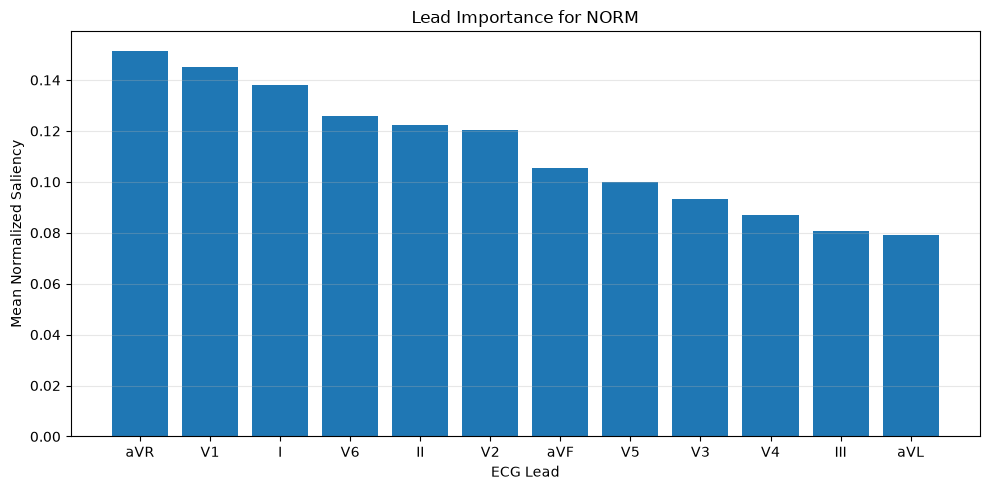

In [20]:
plt.figure(figsize=(10, 5))

plt.bar(lead_importance_df["lead"], lead_importance_df["importance"])

plt.xlabel("ECG Lead")

plt.ylabel("Mean Normalized Saliency")

plt.title(f"Lead Importance for {selected_class}")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

In [21]:
lead_importance_df.to_csv(
    INTERPRETATION_DIR / f"lead_importance_{selected_class}.csv", index=False
)

print("Saved lead importance.")

Saved lead importance.


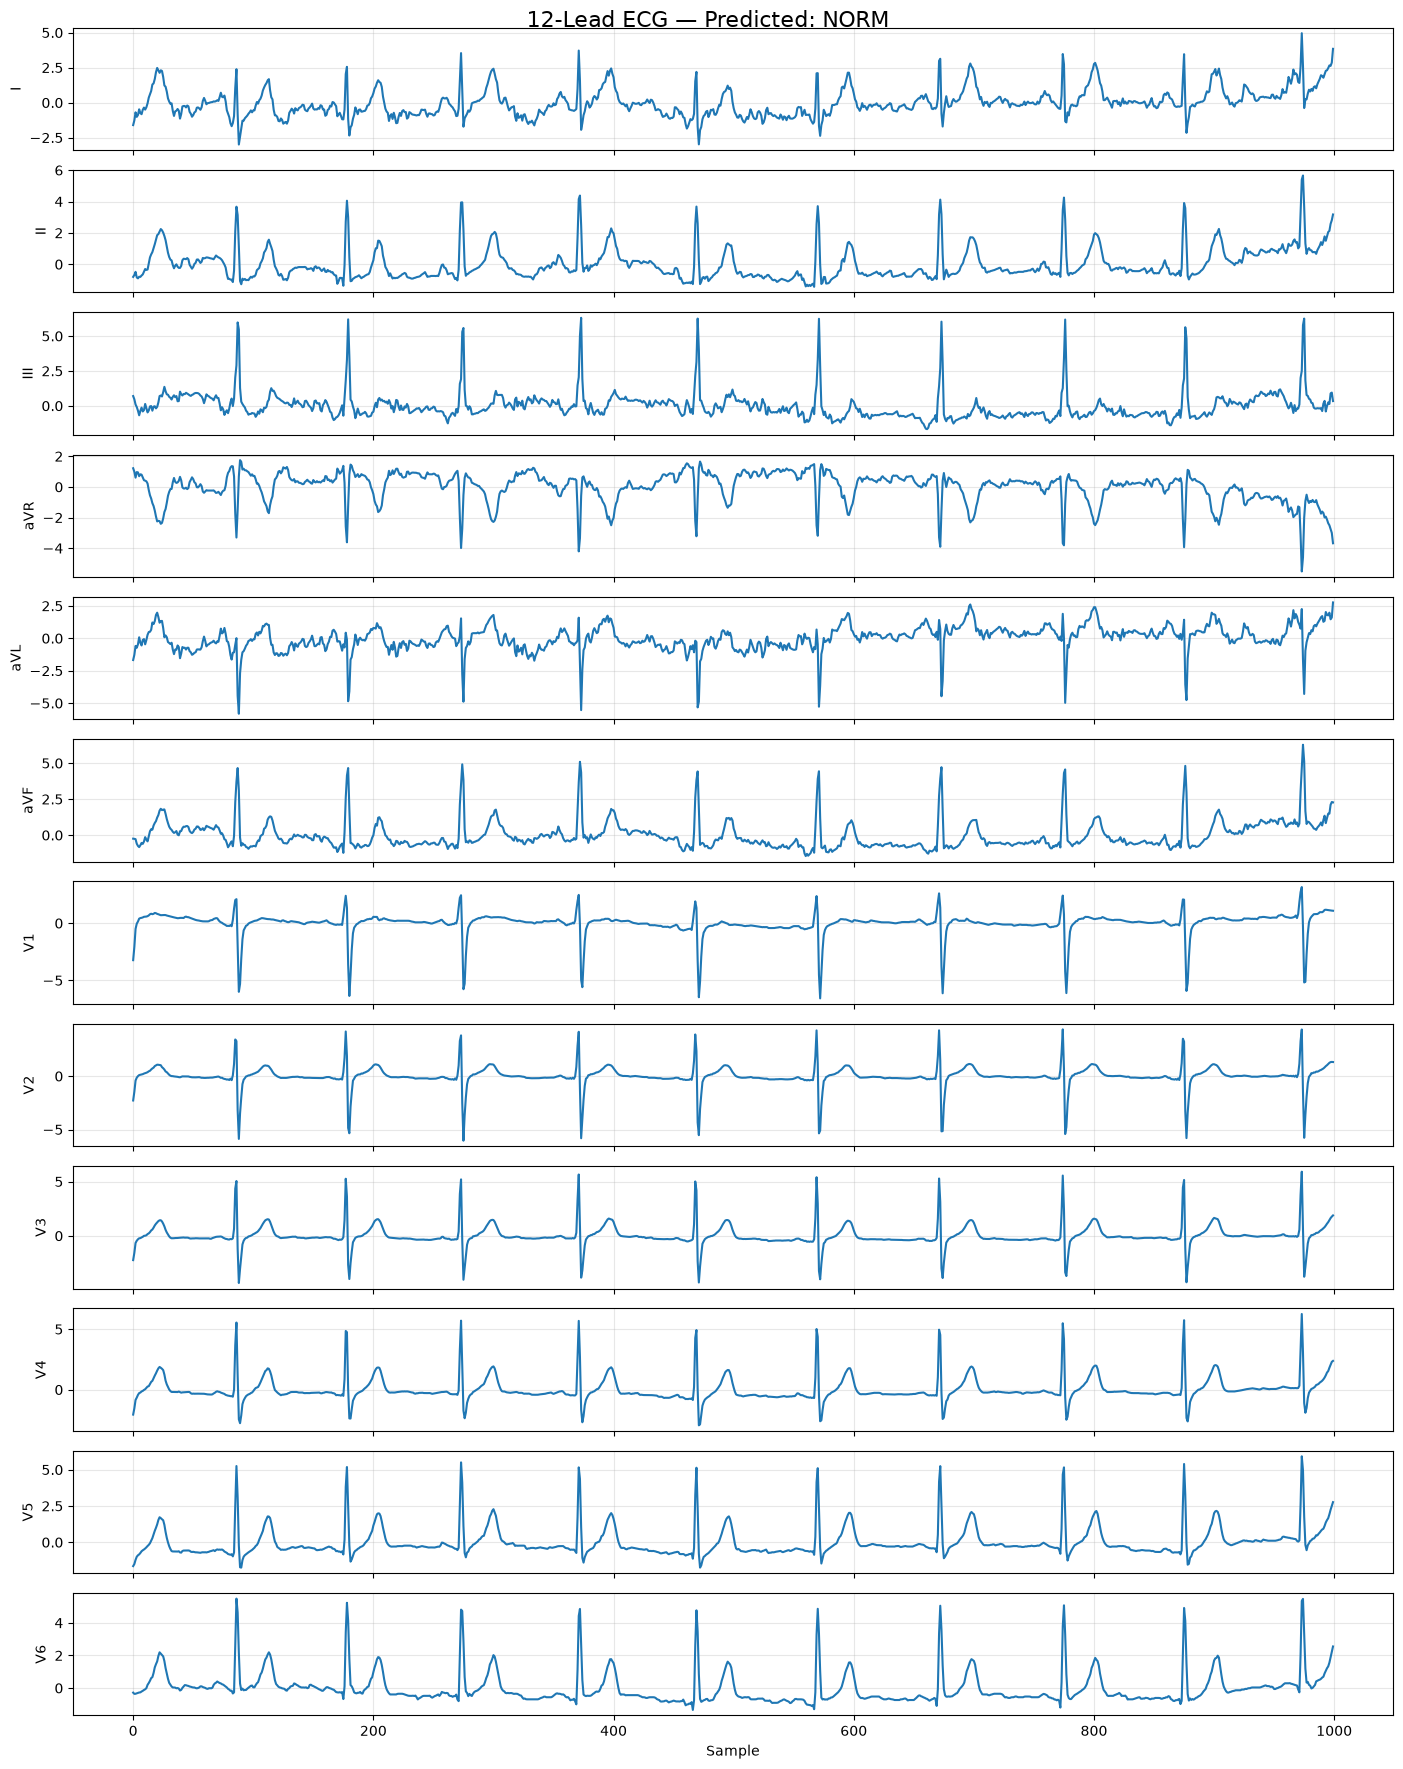

In [22]:
signal = X.numpy()

fig, axes = plt.subplots(12, 1, figsize=(14, 18), sharex=True)

for i, ax in enumerate(axes):

    ax.plot(signal[i])

    ax.set_ylabel(lead_names[i])

    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sample")

fig.suptitle(f"12-Lead ECG — " f"Predicted: {selected_class}", fontsize=16)

plt.tight_layout()

plt.show()

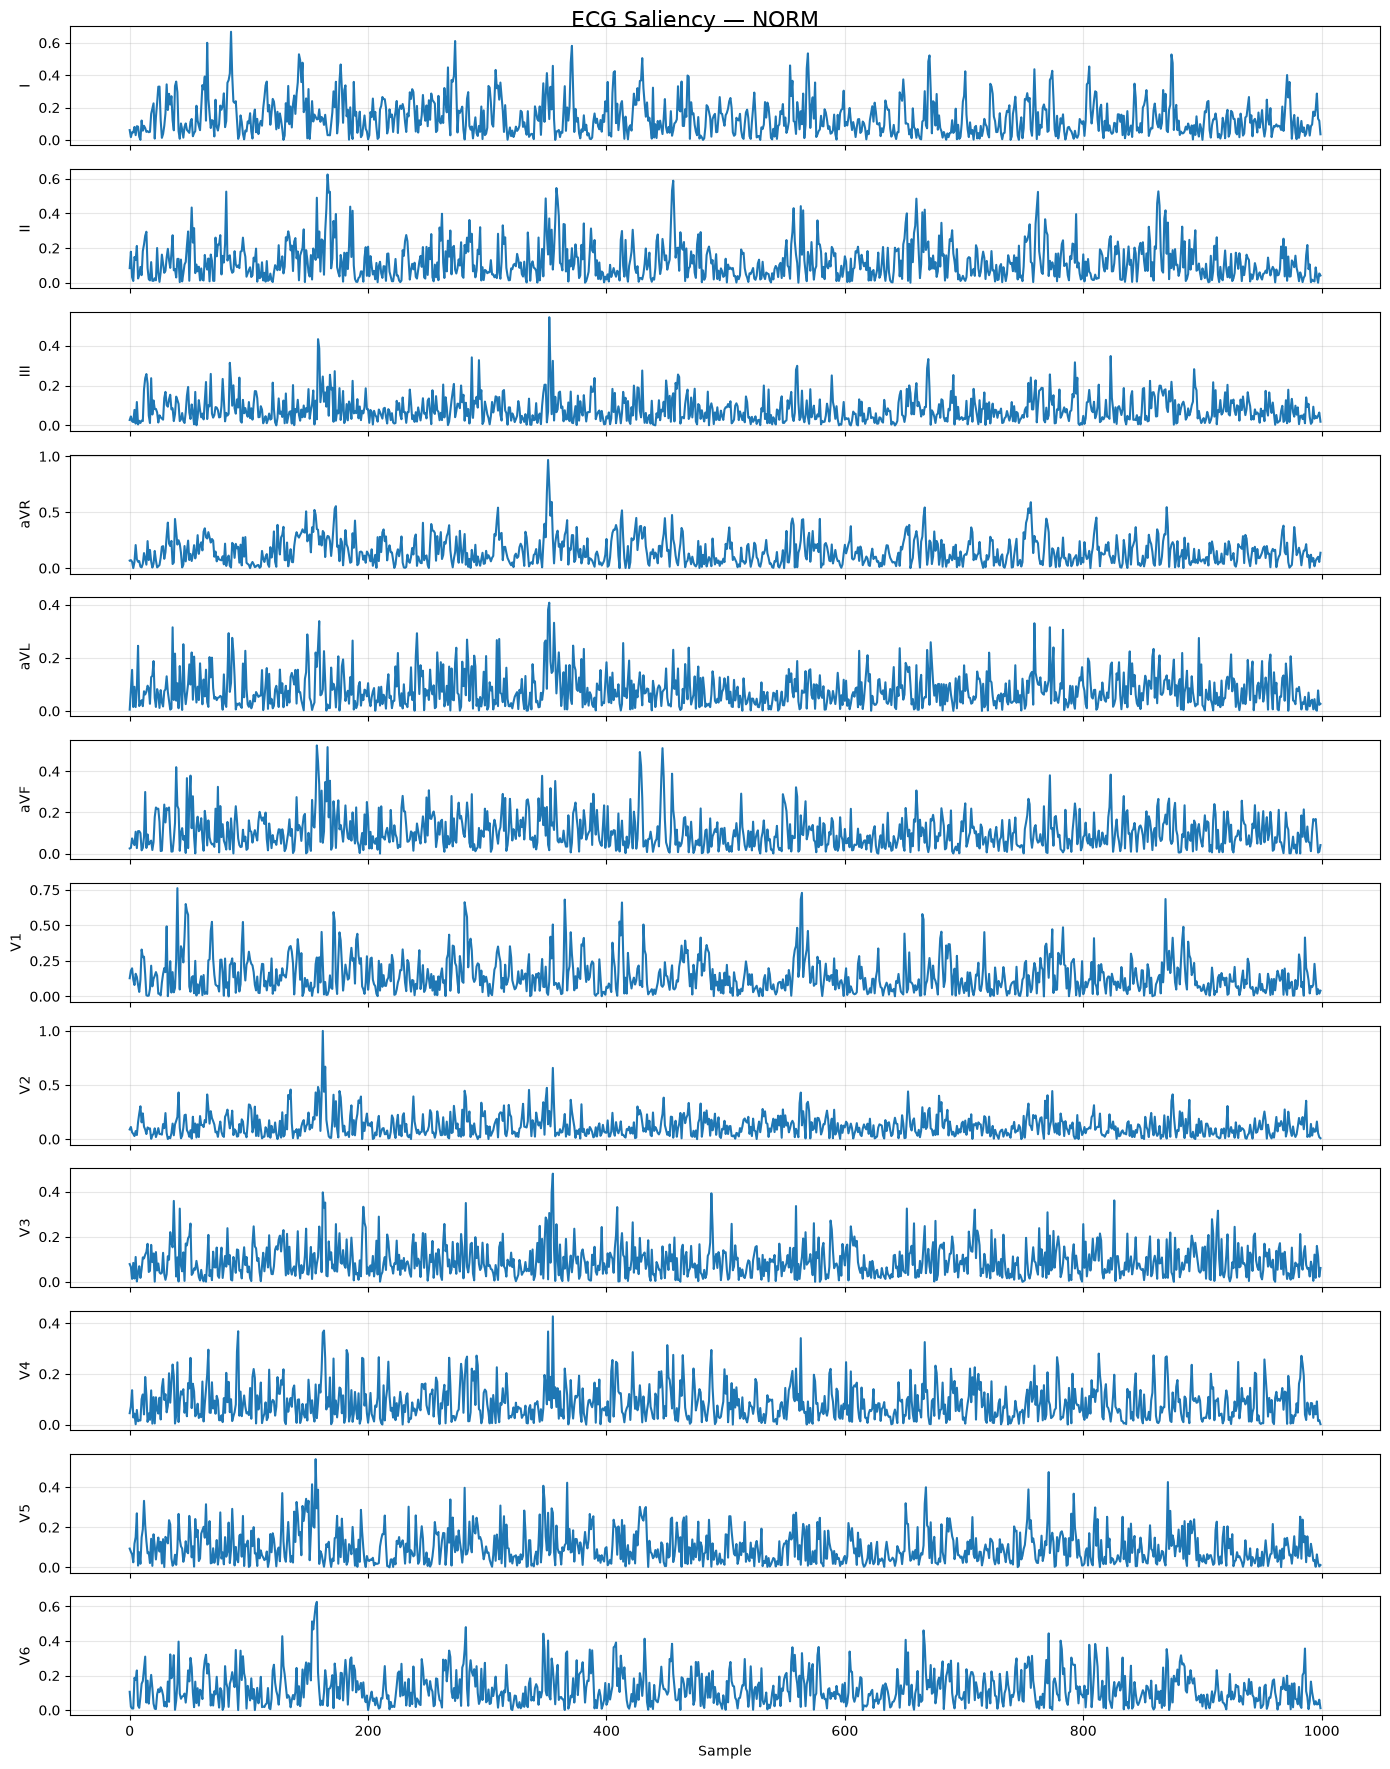

In [23]:
fig, axes = plt.subplots(12, 1, figsize=(14, 18), sharex=True)

for i, ax in enumerate(axes):

    ax.plot(saliency_normalized[i])

    ax.set_ylabel(lead_names[i])

    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sample")

fig.suptitle(f"ECG Saliency — {selected_class}", fontsize=16)

plt.tight_layout()

plt.show()

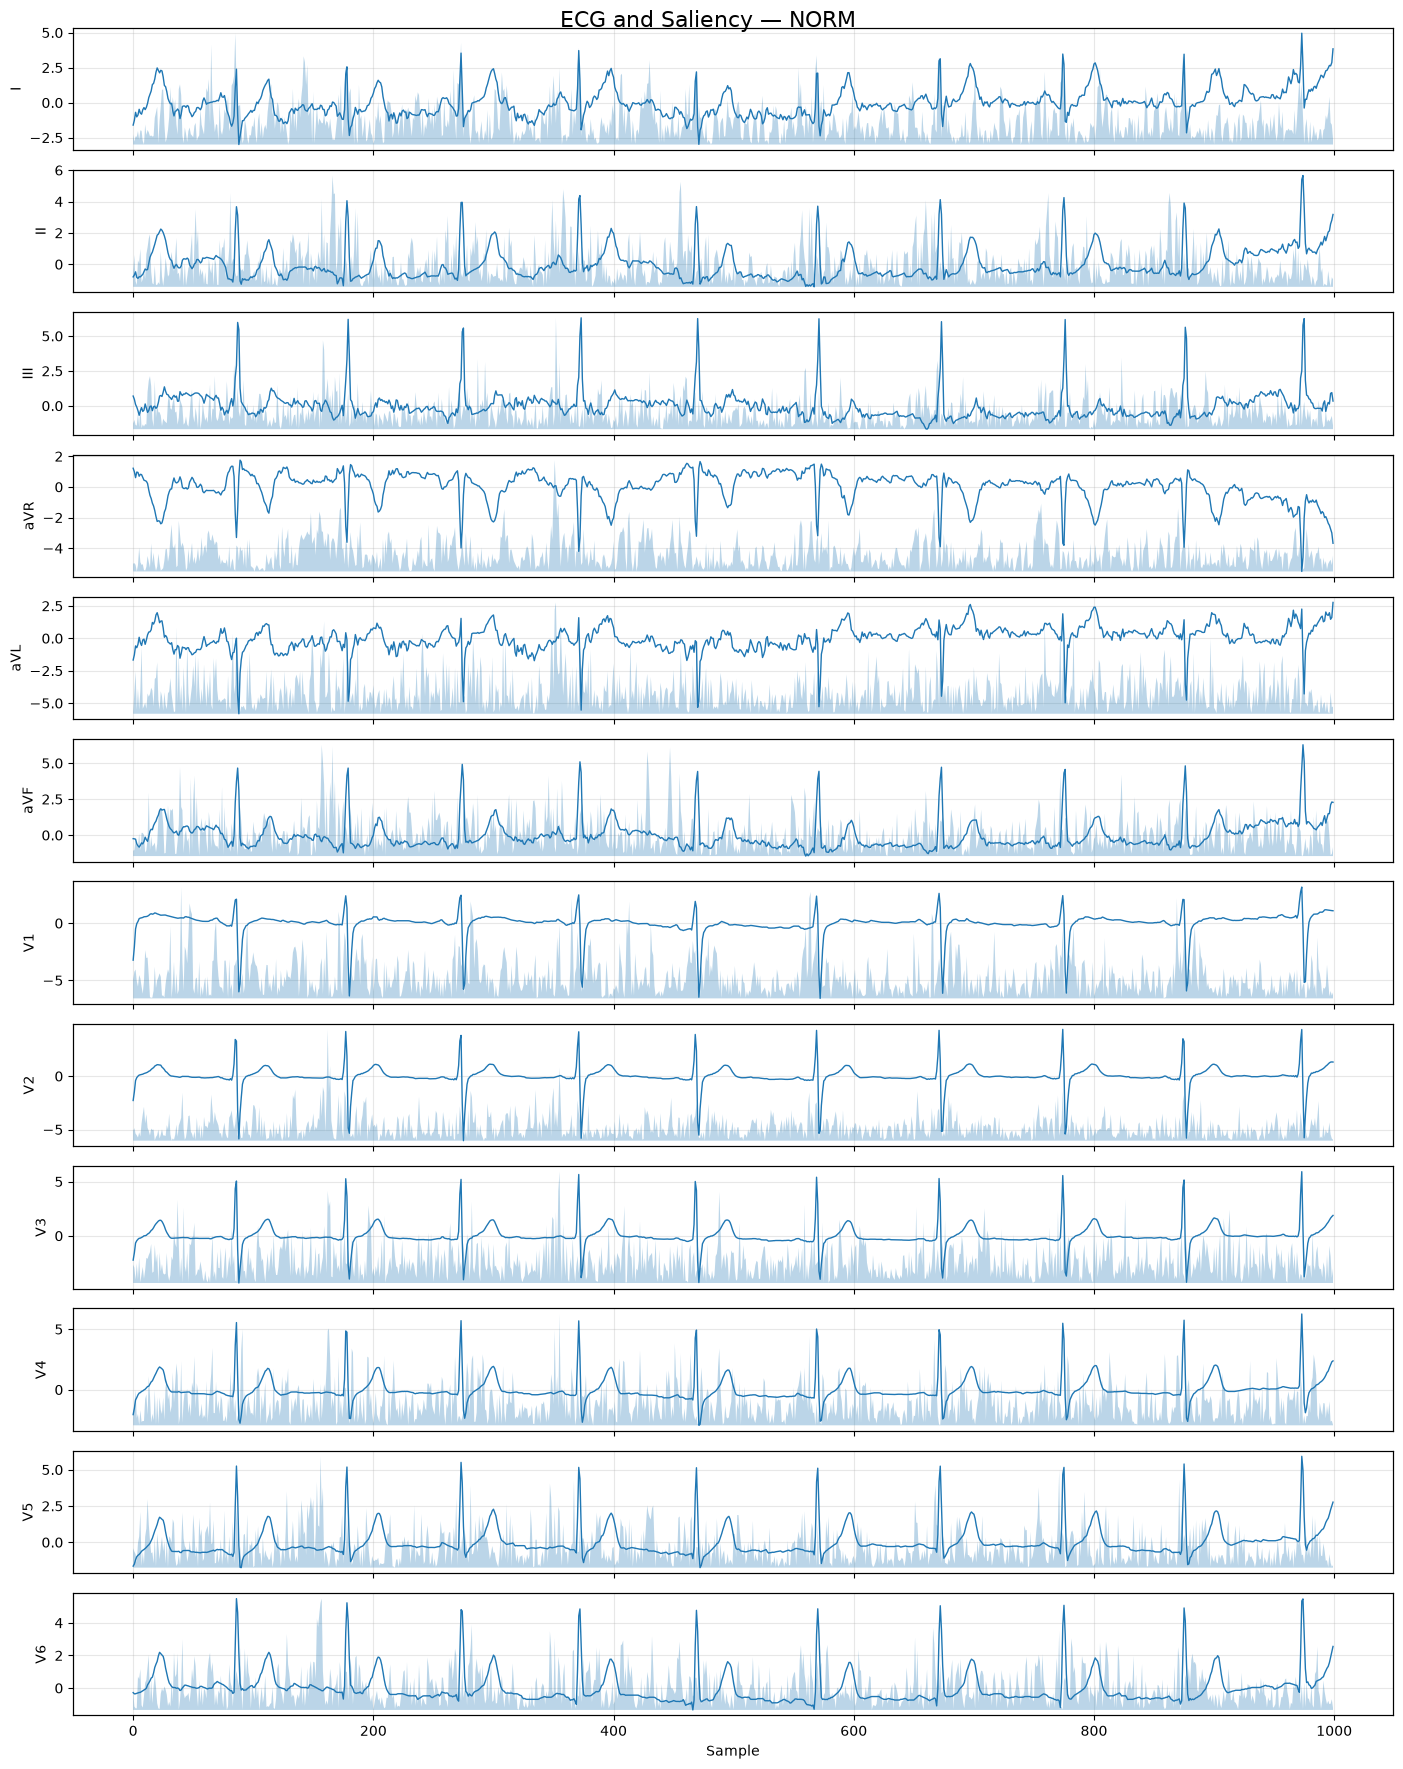

In [24]:
fig, axes = plt.subplots(12, 1, figsize=(14, 18), sharex=True)

for i, ax in enumerate(axes):

    ax.plot(signal[i], linewidth=1)

    ax2 = ax.twinx()

    ax2.fill_between(np.arange(signal.shape[1]), saliency_normalized[i], alpha=0.3)

    ax.set_ylabel(lead_names[i])

    ax.grid(alpha=0.3)

    ax2.set_yticks([])

axes[-1].set_xlabel("Sample")

fig.suptitle(f"ECG and Saliency — " f"{selected_class}", fontsize=16)

plt.tight_layout()

plt.show()

In [25]:
figure_path = (
    INTERPRETATION_DIR / f"saliency_{selected_class}_sample_{sample_index}.png"
)

fig.savefig(figure_path, dpi=200, bbox_inches="tight")

print("Saved:", figure_path)

Saved: ../reports/interpretation/saliency_NORM_sample_0.png


In [26]:
representative_indices = {}

for class_index, class_name in enumerate(TARGET_CLASSES):

    matches = np.where(test_df[label_columns[class_index]].values == 1)[0]

    if len(matches) > 0:

        representative_indices[class_name] = int(matches[0])

representative_indices

{'NORM': 0, 'MI': 5, 'STTC': 14, 'CD': 6, 'HYP': 24}

In [27]:
def generate_saliency(model, dataset, sample_index, class_index, device):

    X, y = dataset[sample_index]

    X_input = X.unsqueeze(0).to(device)

    X_input.requires_grad_()

    model.zero_grad()

    logits = model(X_input)

    score = logits[0, class_index]

    score.backward()

    saliency = X_input.grad.detach().abs().cpu().numpy()[0]

    saliency = saliency / (saliency.max() + 1e-8)

    return (
        X.numpy(),
        y.numpy(),
        saliency,
        torch.sigmoid(logits).detach().cpu().numpy()[0],
    )

In [28]:
all_lead_importance = []

for class_index, class_name in enumerate(TARGET_CLASSES):

    sample_index = representative_indices[class_name]

    signal, true_labels, saliency, probabilities = generate_saliency(
        model, test_dataset, sample_index, class_index, device
    )

    importance = saliency.mean(axis=1)

    for lead, value in zip(lead_names, importance):

        all_lead_importance.append(
            {"class": class_name, "lead": lead, "importance": value}
        )

lead_importance_all_df = pd.DataFrame(all_lead_importance)

lead_importance_all_df.head()

,class,lead,importance
0,NORM,I,0.137981
1,NORM,II,0.122164
2,NORM,III,0.080598
3,NORM,aVR,0.151545
4,NORM,aVL,0.079329


In [29]:
lead_importance_all_df.to_csv(
    INTERPRETATION_DIR / "ptbxl_cnn_lead_importance.csv", index=False
)

print("Saved all-class lead importance.")

Saved all-class lead importance.


In [30]:
summary_rows = []

for class_name in TARGET_CLASSES:

    class_data = lead_importance_all_df[
        lead_importance_all_df["class"] == class_name
    ].sort_values("importance", ascending=False)

    top_lead = class_data.iloc[0]

    summary_rows.append(
        {
            "class": class_name,
            "top_lead": top_lead["lead"],
            "top_lead_importance": (top_lead["importance"]),
        }
    )

interpretation_summary = pd.DataFrame(summary_rows)

interpretation_summary

,class,top_lead,top_lead_importance
0,NORM,aVR,0.151545
1,MI,V2,0.067743
2,STTC,aVR,0.187014
3,CD,V1,0.100835
4,HYP,V1,0.178855


In [31]:
interpretation_summary.to_csv(
    INTERPRETATION_DIR / "ptbxl_cnn_interpretation_summary.csv", index=False
)

print("Interpretation summary saved.")

Interpretation summary saved.


In [32]:
print("=" * 60)
print("PTB-XL CNN MODEL INTERPRETATION")
print("=" * 60)

print("\nRepresentative samples:")

for class_name, index in representative_indices.items():

    print(f"{class_name}: " f"test sample {index}")

print("\nInterpretation summary:")

print(interpretation_summary.to_string(index=False))

print("\nSaved to:")

print(INTERPRETATION_DIR)

PTB-XL CNN MODEL INTERPRETATION

Representative samples:
NORM: test sample 0
MI: test sample 5
STTC: test sample 14
CD: test sample 6
HYP: test sample 24

Interpretation summary:
class top_lead  top_lead_importance
 NORM      aVR             0.151545
   MI       V2             0.067743
 STTC      aVR             0.187014
   CD       V1             0.100835
  HYP       V1             0.178855

Saved to:
../reports/interpretation
